# 02 · Modélisation
**Objectif :** prédire si un réglage de réseau est instable (classe positive = 1), à partir des variables de réglage.
Ce notebook couvre l'axe 4 (modèle) et la partie « métriques » de l'axe 5.

Démarche : split → pipeline → baseline → 3 modèles comparés en validation croisée → réglage d'un hyperparamètre → diagnostic → **un seul passage sur le jeu de test**.

## 1. Imports, chemins, graine

In [1]:
import sys
sys.path.append("..")                      # pour importer le dossier src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             average_precision_score, recall_score, precision_score, f1_score)

from src.utils import charger_donnees, ajouter_variables, colonnes_modele

RANDOM_STATE = 42
DATA_PATH = Path("..") / "data" / "Data_for_UCI_named.csv"
REPORTS = Path("..") / "reports"
REPORTS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

## 2. Données et variables
- Variables données au modèle : les 12 variables de réglage + 3 variables construites (voir notebook 01, section 7).
- **Exclues : `stab` (fuite) et `stabf` (la cible elle-même).**

In [2]:
df = ajouter_variables(charger_donnees(DATA_PATH))
FEATURES = colonnes_modele()
X = df[FEATURES]
y = df["instable"]          # 1 = instable
print("Variables utilisées :", FEATURES)
print("Part d'instables :", round(y.mean(), 3))

Variables utilisées : ['tau1', 'tau2', 'tau3', 'tau4', 'p1', 'p2', 'p3', 'p4', 'g1', 'g2', 'g3', 'g4', 'tau_moyen', 'g_moyen', 'tau_g_moyen']
Part d'instables : 0.638


## 3. Split train / test (en premier, stratifié)
Le jeu de test (20 %) est mis de côté. Il ne sert **qu'une seule fois**, à la section 9.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train :", X_train.shape, "| part d'instables :", round(y_train.mean(), 3))
print("Test  :", X_test.shape, "| part d'instables :", round(y_test.mean(), 3))

Train : (8000, 15) | part d'instables : 0.638
Test  : (2000, 15) | part d'instables : 0.638


## 4. Pipelines et modèles comparés
Toute la préparation (ici la standardisation) est **dans le pipeline** : elle est apprise sur le train de chaque pli, jamais sur les données de validation.

| Modèle | Rôle |
|---|---|
| Baseline « toujours instable » | Équivaut à la situation actuelle : on simule tous les réglages. Référence plancher. |
| Régression logistique | Modèle linéaire, interprétable |
| Arbre sans `max_depth` | Montre le surapprentissage |
| Random Forest (`max_depth=8`) | Modèle à base d'arbres |

In [4]:
def faire_pipeline(clf):
    prep = ColumnTransformer([("num", StandardScaler(), FEATURES)])
    return Pipeline([("prep", prep), ("clf", clf)])

modeles = {
    "Baseline (toujours instable)": faire_pipeline(DummyClassifier(strategy="most_frequent")),
    "Régression logistique": faire_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Arbre (sans max_depth)": faire_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "Random Forest (max_depth=8)": faire_pipeline(
        RandomForestClassifier(n_estimators=200, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1)),
}

## 5. Validation croisée à 5 plis (sur le train uniquement)
- **Métrique principale pour départager les modèles : PR-AUC** (qualité du classement, indépendante du seuil). Le seuil de décision sera choisi à l'axe 6 avec les coûts (notebook 03).
- Garde-fous : **recall** sur la classe « instable » (rater un réglage instable est grave) et **precision**.
- L'accuracy n'est pas utilisée pour décider.
- **Attention :** la baseline « toujours instable » a un recall de 1,00 par construction. Ce recall ne vaut rien, car elle ne fait économiser aucune simulation. Il faut lire le recall avec la precision.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"recall": "recall", "precision": "precision", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}

lignes = []
for nom, est in modeles.items():
    r = cross_validate(est, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
    lignes.append({
        "Modèle": nom,
        "F1 train": r["train_f1"].mean(),
        "F1 CV (moy ± é.-t.)": f"{r['test_f1'].mean():.3f} ± {r['test_f1'].std():.3f}",
        "Recall CV": f"{r['test_recall'].mean():.3f} ± {r['test_recall'].std():.3f}",
        "Precision CV": f"{r['test_precision'].mean():.3f} ± {r['test_precision'].std():.3f}",
        "ROC-AUC CV": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}",
        "PR-AUC CV": f"{r['test_pr_auc'].mean():.3f} ± {r['test_pr_auc'].std():.3f}",
    })
tableau_cv = pd.DataFrame(lignes).set_index("Modèle")
tableau_cv["F1 train"] = tableau_cv["F1 train"].round(3)
tableau_cv

,F1 train,F1 CV (moy ± é.-t.),Recall CV,Precision CV,ROC-AUC CV,PR-AUC CV
Modèle,,,,,,
Baseline (toujours instable),0.779,0.779 ± 0.000,1.000 ± 0.000,0.638 ± 0.000,0.500 ± 0.000,0.638 ± 0.000
Régression logistique,0.874,0.873 ± 0.012,0.838 ± 0.016,0.911 ± 0.009,0.932 ± 0.007,0.960 ± 0.004
Arbre (sans max_depth),1.000,0.909 ± 0.007,0.908 ± 0.006,0.910 ± 0.010,0.874 ± 0.012,0.885 ± 0.010
Random Forest (max_depth=8),0.966,0.925 ± 0.005,0.947 ± 0.007,0.905 ± 0.008,0.971 ± 0.002,0.984 ± 0.001


**Lecture (à rédiger) :**
- Quel modèle bat la baseline, et de combien ?
- Quel modèle surapprend (F1 train très supérieur au F1 CV, écart-type élevé) ?
- Quel modèle a la meilleure PR-AUC ? C'est celui que l'on retient et que l'on règle ensuite.

## 6. Réglage d'hyperparamètres (Random Forest)
On teste `max_depth` et `min_samples_leaf` avec la même validation croisée, sur le train. Score de sélection : PR-AUC.

In [6]:
pipe_rf = faire_pipeline(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
grille = {"clf__max_depth": [3, 5, 8, 12, None],
          "clf__min_samples_leaf": [1, 5]}

recherche = GridSearchCV(pipe_rf, grille, cv=cv, scoring="average_precision",
                         return_train_score=True, refit=True)
recherche.fit(X_train, y_train)

print("Meilleurs paramètres :", recherche.best_params_)
print("PR-AUC CV du meilleur modèle :", round(recherche.best_score_, 3))
modele_final = recherche.best_estimator_      # déjà réentraîné sur tout le train

Meilleurs paramètres : {'clf__max_depth': None, 'clf__min_samples_leaf': 1}
PR-AUC CV du meilleur modèle : 0.989


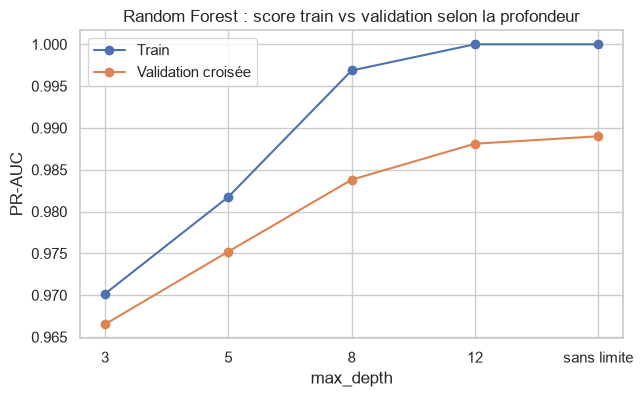

In [7]:
res = pd.DataFrame(recherche.cv_results_)
sous = res[res["param_clf__min_samples_leaf"] == 1].copy()
sous["profondeur"] = ["sans limite" if (v is None or pd.isna(v)) else str(int(v))
                      for v in sous["param_clf__max_depth"]]

plt.figure(figsize=(7, 4))
plt.plot(sous["profondeur"], sous["mean_train_score"], marker="o", label="Train")
plt.plot(sous["profondeur"], sous["mean_test_score"], marker="o", label="Validation croisée")
plt.xlabel("max_depth")
plt.ylabel("PR-AUC")
plt.title("Random Forest : score train vs validation selon la profondeur")
plt.legend()
plt.show()

**Interprétation (à rédiger) :** à partir de quelle profondeur l'écart entre train et validation grandit-il (surapprentissage) ?
Le sous-apprentissage apparaît-il pour les petites profondeurs ?

## 7. Diagnostic : importance des variables

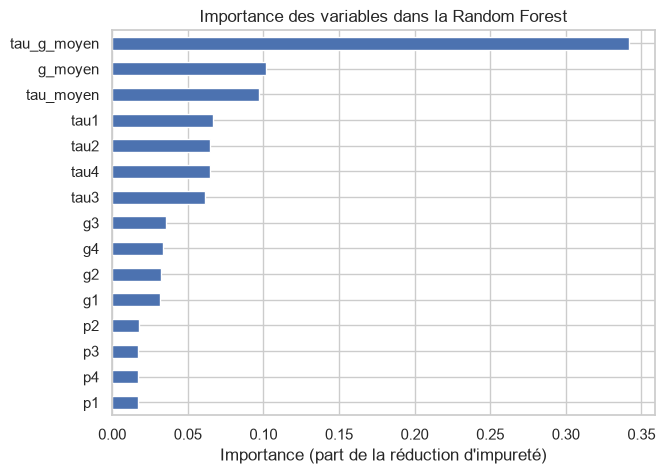

tau_g_moyen    0.342
g_moyen        0.102
tau_moyen      0.097
tau1           0.066
tau2           0.065
tau4           0.065
tau3           0.061
g3             0.036
g4             0.034
g2             0.033
g1             0.031
p2             0.018
p3             0.017
p4             0.017
p1             0.017
dtype: float64

In [8]:
rf = modele_final.named_steps["clf"]
importances = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

plt.figure(figsize=(7, 5))
importances.plot(kind="barh")
plt.xlabel("Importance (part de la réduction d'impureté)")
plt.title("Importance des variables dans la Random Forest")
plt.show()
importances.sort_values(ascending=False).round(3)

**Interprétation (à rédiger) :** quelles variables pèsent le plus ? Est-ce cohérent avec les corrélations du notebook 01
(tau et g liées à l'instabilité) ? Les variables construites (`tau_moyen`, `g_moyen`, `tau_g_moyen`) sont-elles utiles ?

## 8. Diagnostic : analyse des erreurs (sur le train, par validation croisée)
On calcule des probabilités « hors pli » : chaque réglage est prédit par un modèle qui ne l'a pas vu pendant son entraînement.
Ces probabilités serviront au choix du seuil au notebook 03, **sans toucher au jeu de test**.

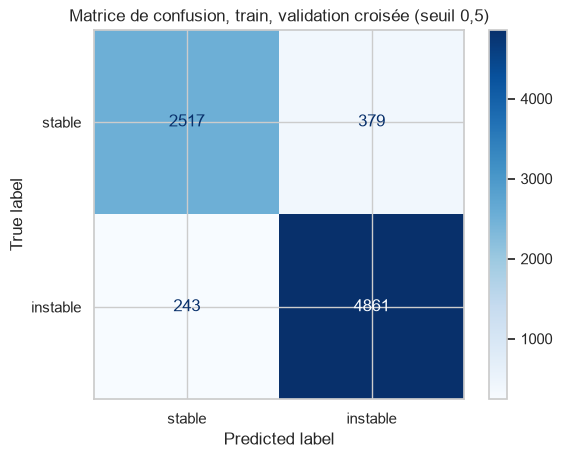

In [9]:
proba_train_oof = cross_val_predict(modele_final, X_train, y_train, cv=cv,
                                    method="predict_proba")[:, 1]
pred_oof = (proba_train_oof >= 0.5).astype(int)

ConfusionMatrixDisplay(confusion_matrix(y_train, pred_oof),
                       display_labels=["stable", "instable"]).plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion, train, validation croisée (seuil 0,5)")
plt.show()

In [10]:
# Les faux négatifs (instables non détectés) : en quoi diffèrent-ils des instables bien détectés ?
masque_fn = (y_train == 1) & (pred_oof == 0)
masque_vp = (y_train == 1) & (pred_oof == 1)
print("Faux négatifs :", int(masque_fn.sum()), "| vrais positifs :", int(masque_vp.sum()))

comparaison = pd.DataFrame({
    "Faux négatifs (moyenne)": X_train[masque_fn].mean(),
    "Instables bien détectés (moyenne)": X_train[masque_vp].mean(),
}).round(3)
comparaison

Faux négatifs : 243 | vrais positifs : 4861


,Faux négatifs (moyenne),Instables bien détectés (moyenne)
tau1,4.284,5.816
tau2,4.271,5.836
tau3,4.185,5.832
tau4,4.243,5.785
p1,3.749,3.760
p2,-1.217,-1.251
p3,-1.254,-1.252
p4,-1.278,-1.257
g1,0.452,0.570
g2,0.482,0.576


**Interprétation (à rédiger) :** les instables ratés sont-ils des cas « limites » (variables proches de celles des stables) ?
Que cela dit-il de la limite du modèle ?

## 9. Évaluation finale sur le jeu de test (un seul passage)
On évalue **uniquement le modèle final** ci-dessus, une seule fois. Aucun réglage n'est modifié après avoir regardé ces chiffres.

ROC-AUC test : 0.987
PR-AUC test  : 0.993
Au seuil 0,5 -> recall : 0.968 | precision : 0.933 | F1 : 0.95


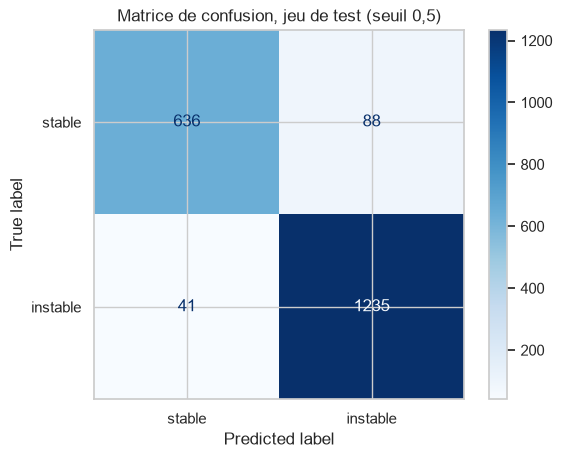

In [11]:
proba_test = modele_final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= 0.5).astype(int)

print("ROC-AUC test :", round(roc_auc_score(y_test, proba_test), 3))
print("PR-AUC test  :", round(average_precision_score(y_test, proba_test), 3))
print("Au seuil 0,5 -> recall :", round(recall_score(y_test, pred_test), 3),
      "| precision :", round(precision_score(y_test, pred_test), 3),
      "| F1 :", round(f1_score(y_test, pred_test), 3))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test),
                       display_labels=["stable", "instable"]).plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion, jeu de test (seuil 0,5)")
plt.show()

**Lecture (à rédiger) :** les scores de test sont-ils proches de ceux de la validation croisée ? Si oui, le modèle généralise.
Traduction métier : « sur 100 réglages instables, le modèle en détecte X au seuil 0,5 ». Le seuil sera optimisé au notebook 03.

## 10. Sauvegarde pour le notebook 03

In [12]:
pd.DataFrame({"y": y_train.values, "proba": proba_train_oof}).to_csv(REPORTS / "proba_train_oof.csv", index=False)
pd.DataFrame({"y": y_test.values, "proba": proba_test}).to_csv(REPORTS / "proba_test.csv", index=False)
tableau_cv.to_csv(REPORTS / "comparaison_modeles_cv.csv")
joblib.dump(modele_final, REPORTS / "modele_final.joblib")
print("Fichiers enregistrés dans", REPORTS.resolve())

Fichiers enregistrés dans C:\Users\baba\stabilite-reseau-electrique\reports
